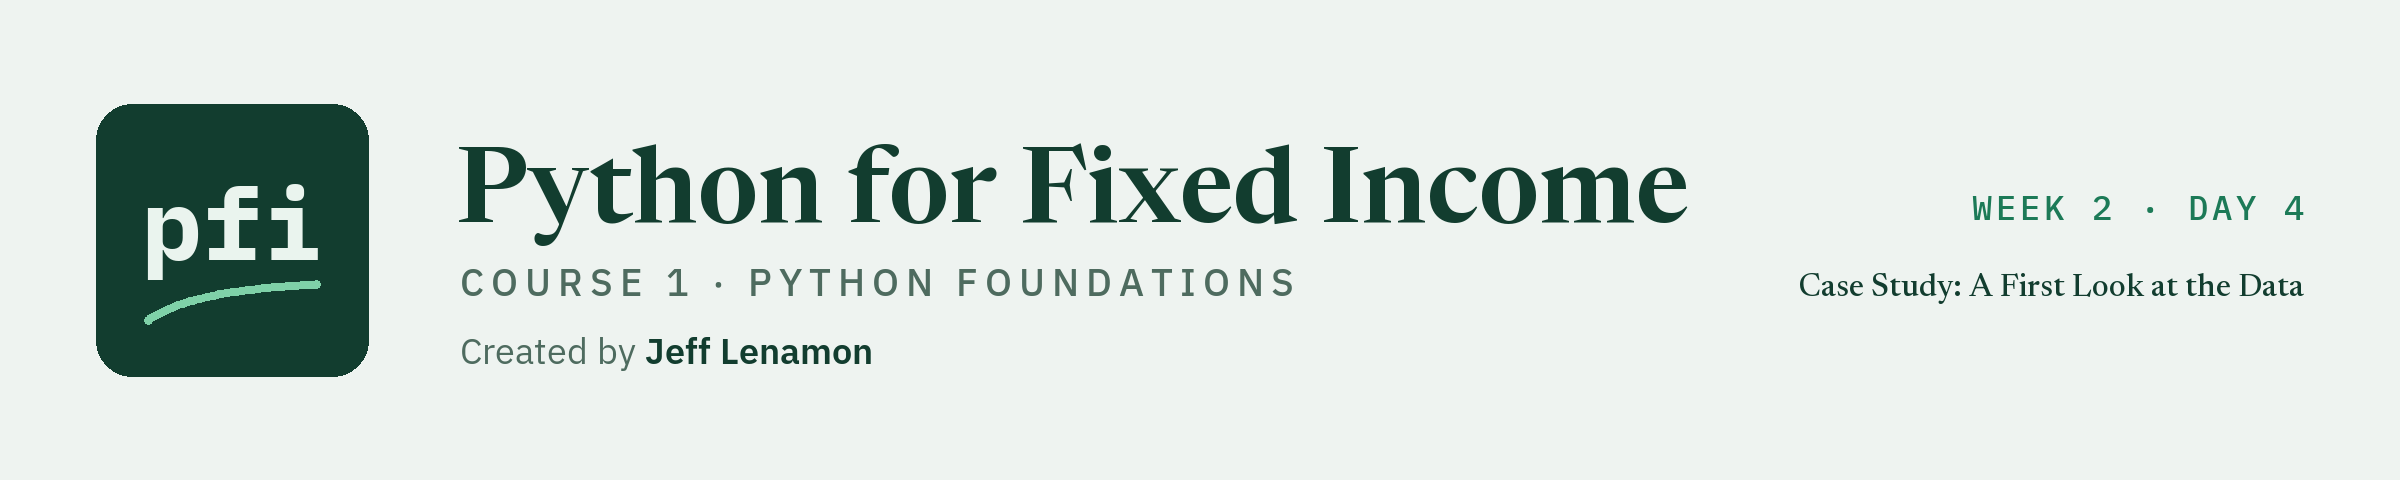

# Case Study: A First Look at the Data

Week 2, Day 4. Three tables arrive from three systems, and each one gets a careful look before anything is joined.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day4/09_case_study_first_look_at_the_data.ipynb)

## Problem Definition

### Context

The desk lead's fourteenth note:

> Yesterday we checked the joins; nobody looked at each file on its own. The three systems now send these files every month, and nobody tells us what is wrong with them. Before tomorrow's report, tell me what each file holds, whether anything is missing or doubled, and that the face still ties to our 489,000,000. Give me the bonds to watch: below par, long-dated, small. Will the three join without losing or doubling a bond? And write the checks so they run themselves next month.

### Objective

You are the desk's analyst.
Nothing is joined today: look at each table, test the keys, and write the findings as checks.

### The Data

As of 2026-09-30; the issuers and CUSIPs are invented.

<table align="left">
<tr><th align="left">File</th><th align="left">Sent by</th><th align="left">Columns (units)</th></tr>
<tr><td align="left"><code>positions.csv</code></td><td align="left">trading</td><td align="left"><code>cusip</code>, <code>ticker</code>, <code>coupon</code> (percent), <code>maturity</code>, <code>price</code> (per 100 of face), <code>par_held</code> (face held)</td></tr>
<tr><td align="left"><code>issuers.csv</code></td><td align="left">reference data</td><td align="left"><code>ticker</code>, <code>issuer</code>, <code>sector</code>, <code>country</code>, <code>rating</code> (letters)</td></tr>
<tr><td align="left"><code>ratings.csv</code></td><td align="left">the rating scale</td><td align="left"><code>rating</code>, <code>score</code> (1 for AAA, one more per notch), <code>bucket</code>, <code>grade</code></td></tr>
</table>
<br clear="left">

One rating per issuer here; in real data a bond can sit a notch away from its issuer.

### How We Will Work

![Six steps left to right, each with its tool: first rows with head, shape, types with info, summary with describe, gaps and repeats with isna and duplicated, the key with is_unique and isin. Under them three file cards, positions 200 rows, issuers 150, ratings 18, each run through all six steps](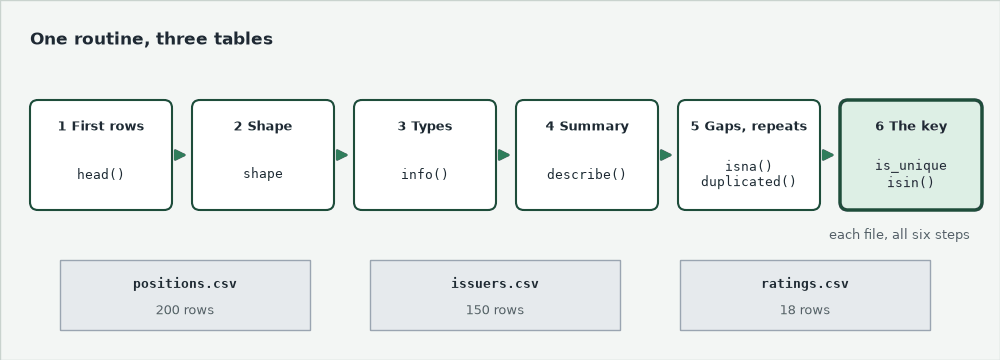)

Every table gets the same six steps, in the same order.

**Look first, join tomorrow: the same six steps for every table.**

## 9.1 Loading the Three Tables

### Three Files, Three Shapes

Q. Read the three files. How large is each?

In [1]:
import os

import pandas as pd

# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/positions.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# one table per file; shape gives rows, then columns, as in week 1's Day 5
positions = pd.read_csv(data_folder + 'positions.csv')
issuers = pd.read_csv(data_folder + 'issuers.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(positions.shape, issuers.shape, ratings.shape)

(200, 6) (150, 5) (18, 4)


No error says the files were found, not what is inside them.
This notebook was saved with pandas 3.0.6; an older pandas, as Colab may run, words a few outputs differently.

**Three sizes, so a row stands for something different in each table. Find out what.**

## 9.2 The Positions Table

### What One Row Is

Q. Show the first rows of the file the desk cares about most.

In [2]:
# head(): the first five rows, and every column name spelled as you must type it
positions.head()

,cusip,ticker,coupon,maturity,price,par_held
0,99080CAE8,BEZE,7.000,2032-06-18,106.727,5000000
1,99049XAE2,BEZH,8.125,2029-04-17,97.556,250000
2,99039NAC0,BEZL,5.125,2030-06-03,98.730,1500000
3,99039NAG1,BEZL,6.125,2053-04-09,92.261,500000
4,99034IAD4,BEZN,4.625,2036-04-05,92.883,2500000


One row is one bond the desk holds: the BEZE 7% of 2032-06-18 at 106.727, 5,000,000 of face.
The CUSIP names the bond; the ticker names its issuer, and BEZL already appears twice.

**One row, one bond held: the CUSIP names it.**

### Types and Gaps

Q. What type is each column, and is anything missing?

In [3]:
# info(), as in week 1's Day 5: each column's count of values and its type
positions.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   cusip     200 non-null    str    
 1   ticker    200 non-null    str    
 2   coupon    200 non-null    float64
 3   maturity  200 non-null    str    
 4   price     200 non-null    float64
 5   par_held  200 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 14.0 KB


Every column holds 200 non-null values, and non-null means not missing.
`maturity` is `str`, text, as Combining Part 2 found in the holdings.

Q. Convert the maturities to dates without changing the table. When is the first, and the last?

In [4]:
# a separate Series of dates: positions keeps its maturity as text
maturity_dates = pd.to_datetime(positions['maturity'])
as_of = pd.Timestamp('2026-09-30')
# .date() shows a date without the time of day
print('First:', maturity_dates.min().date(), 'Last:', maturity_dates.max().date())
print('Matured already:', (maturity_dates <= as_of).sum())

First: 2027-10-02 Last: 2056-08-23
Matured already: 0


All 200 converted with no error, so every maturity is a real date in one layout.

**Numbers ready; the maturity is text, converted on the side.**

### The Range of the Numbers

Q. Summarize the number columns, then draw the prices.

In [5]:
# describe(), as in week 1's Day 5: count, mean, spread, and quartiles of each number column
positions.describe()

,coupon,price,par_held
count,200.000000,200.000000,2.000000e+02
mean,5.937500,98.828295,2.445000e+06
std,1.648435,7.404931,1.366818e+06
min,3.250000,62.045000,2.500000e+05
25%,4.750000,95.140000,1.500000e+06
50%,5.687500,99.416000,2.250000e+06
75%,6.875000,103.004000,3.500000e+06
max,11.000000,119.131000,5.000000e+06


The three text columns are left out, with no message.
`2.445000e+06` is scientific notation, as in week 1's Day 5: the average position is 2,445,000 of face.

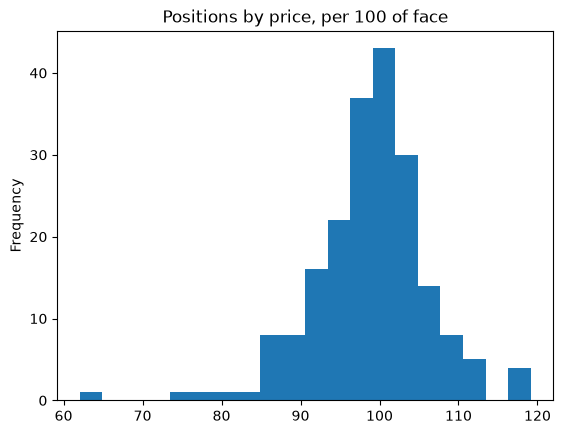

In [6]:
# plot.hist(), as in NumPy Part 1: how many bonds fall in each of 20 price bins
chart = positions['price'].plot.hist(bins=20, title='Positions by price, per 100 of face')

A hill from about 93 to 102 around the mean of 98.83, and one bar alone at the far left, three empty bins after it.

Q. Which bonds sit at the bottom?

In [7]:
# nsmallest(), as in pandas Part 2: the three lowest prices
positions.nsmallest(3, 'price')

,cusip,ticker,coupon,maturity,price,par_held
17,99009JAA9,CLDB,9.500,2034-12-06,62.045,3000000
117,99054CAG5,NEVX,3.875,2048-01-06,73.873,1000000
150,99053BAB9,SYLX,3.625,2055-09-03,76.903,4500000


CLDB at 62.045, nearly 12 points under the next: the same three pandas Part 2 found in the holdings file.

**One price sits far below the rest: CLDB. The files show it; they cannot say why, so the analyst asks the desk.**

### `describe()` on Text

**Predict 1**

Q. The next cell runs `describe()` on the three text columns, `cusip`, `ticker`, and `maturity`. What comes back?

A) An error: text has no mean.
B) An empty table.
C) A different summary, one that counts.

In [8]:
# the three text columns, by a list of names
positions[['cusip', 'ticker', 'maturity']].describe()

,cusip,ticker,maturity
count,200,200,200
unique,200,115,196
top,99080CAE8,NEVX,2031-03-03
freq,1,6,2


C: for text, `describe()` counts: `unique` is how many distinct values, `top` the most common, and `freq` how often it occurs.
200 distinct CUSIPs in 200 rows, so no CUSIP repeats; 115 tickers, NEVX on 6 bonds.

### Missing and Repeated Rows

Q. How many values are missing in each column, and is any row an exact copy of another?

In [9]:
# isna(), as in Combining Part 1, now on a whole table; sum() counts each column's True
print(positions.isna().sum())
# duplicated() marks each row that is an exact copy of another row
print('Repeated rows:', positions.duplicated().sum())

cusip       0
ticker      0
coupon      0
maturity    0
price       0
par_held    0
dtype: int64
Repeated rows: 0


A missing price would not stop a total: pandas skips it, and the total comes out too small.
A position sent twice would double its face.

### A Row Sent Twice

**Predict 2**

Q. The next cell stacks the first three rows with a second copy of the third, four rows in all, and runs `duplicated()`. What does it mark?

A) False, False, True, True: both copies.
B) False, False, False, True: the second copy only.
C) A single True: the table holds a repeat.

In [10]:
# the first three rows, then the third again: pd.concat(), as in Combining Part 1
first_three = positions.head(3)
with_repeat = pd.concat([first_three, first_three.tail(1)], ignore_index=True)
with_repeat.duplicated()

0    False
1    False
2    False
3     True
dtype: bool

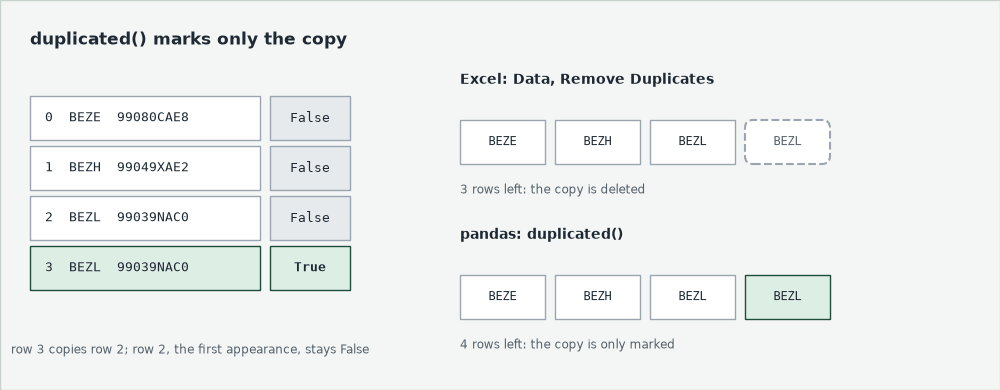

B: only the copy is marked; the first appearance never is.

### The Face Ties

Q. What is the total face held?

In [11]:
# sum() adds the column: the figure tomorrow's joins must keep
total_face = positions['par_held'].sum()
print('Total face held:', total_face)

Total face held: 489000000


pandas Part 2 summed the same 489,000,000 from `holdings.csv`, a different file.

**Nothing missing, nothing doubled, and two systems agree on 489,000,000.**

### Bonds per Issuer

Q. How many tickers have one bond, two bonds, three, and so on?

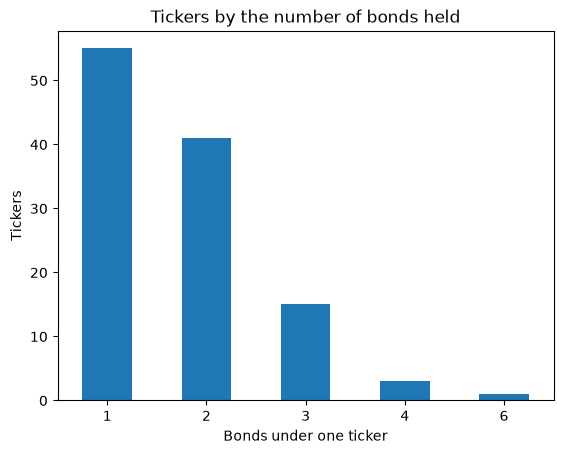

In [12]:
# value_counts(): the bonds under each ticker; then value_counts() of those counts
bonds_per_ticker = positions['ticker'].value_counts()
tickers_by_bonds = bonds_per_ticker.value_counts().sort_index()
# xlabel= and ylabel= name the two axes
chart = tickers_by_bonds.plot.bar(rot=0, title='Tickers by the number of bonds held',
                                  xlabel='Bonds under one ticker', ylabel='Tickers')

55 tickers have one bond and 60 have more; the lone bar at 6 is NEVX.

Q. Show NEVX's bonds.

In [13]:
# a mask on the ticker, as in pandas Part 2
positions[positions['ticker'] == 'NEVX']

,cusip,ticker,coupon,maturity,price,par_held
113,99054CAF7,NEVX,4.625,2031-03-03,97.127,1500000
114,99054CAB6,NEVX,6.250,2032-10-04,104.079,2000000
115,99054CAC4,NEVX,6.250,2034-12-07,103.654,250000
116,99054CAD2,NEVX,6.125,2034-12-14,102.186,1500000
117,99054CAG5,NEVX,3.875,2048-01-06,73.873,1000000
118,99054CAH3,NEVX,5.250,2051-11-24,91.150,3500000


One ticker, six CUSIPs, maturing from 2031 to 2051.

**The ticker repeats; only the CUSIP tells every bond apart.**

### Bonds to Watch

Q. Flag the bonds the note asks for: priced below 100, maturing after 2040, and held under 1,000,000 of face. How many does each flag catch?

In [14]:
# a dictionary of Series, as in pandas Part 1: one True or False column per test
flags = pd.DataFrame({
    'below_par': positions['price'] < 100,
    'long_dated': maturity_dates > pd.Timestamp('2040-12-31'),
    'small': positions['par_held'] < 1000000,
})
flags.sum()

below_par     113
long_dated     34
small          29
dtype: int64

The 113 below par is pandas Part 2's count.

Q. How many flags does each bond carry?

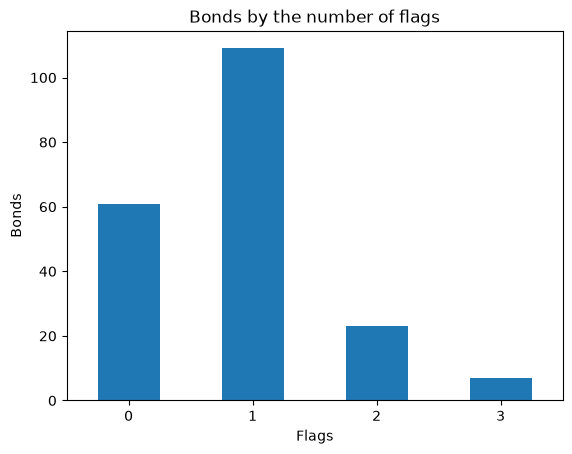

In [15]:
# axis=1 adds across each row, as in NumPy Part 2: one count per bond, 0 to 3
flag_count = flags.sum(axis=1)
bonds_by_flags = flag_count.value_counts().sort_index()
chart = bonds_by_flags.plot.bar(rot=0, title='Bonds by the number of flags',
                                xlabel='Flags', ylabel='Bonds')

61 bonds carry no flag, 109 one, 23 two, and 7 all three.

Q. Which seven carry all three?

In [16]:
# a mask on the count picks the rows, as a mask on a column does
positions[flag_count == 3]

,cusip,ticker,coupon,maturity,price,par_held
3,99039NAG1,BEZL,6.125,2053-04-09,92.261,500000
18,99009JAC5,CLDB,9.250,2050-06-22,95.248,250000
69,99043RAD3,GALR,4.750,2045-10-22,97.898,750000
86,99012MAC3,HULR,5.125,2050-04-27,93.030,750000
137,99001BAF3,QVNE,5.250,2045-02-05,91.884,500000
174,99063LAD1,VRAR,5.125,2045-08-11,95.523,250000
184,99074WAD4,WYXA,6.750,2056-02-23,86.884,750000


**Excel side by side.** Price in column E, the three flags in helper columns G to I:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Size</td><td align="left"><code>positions.shape</code></td><td align="left"><code>Ctrl+End</code>, the last used cell; a column's status-bar Count, 201 with the header</td></tr>
<tr><td align="left">Gaps</td><td align="left"><code>positions['price'].isna().sum()</code></td><td align="left"><code>=COUNTBLANK(E2:E201)</code></td></tr>
<tr><td align="left">Repeats</td><td align="left"><code>positions.duplicated().sum()</code></td><td align="left">Data, Remove Duplicates, which deletes the copies and says how many</td></tr>
<tr><td align="left">Flags</td><td align="left"><code>positions['price'] &lt; 100</code>, <code>flags.sum(axis=1)</code>, <code>flags.sum()</code></td><td align="left"><code>=IF(E2&lt;100, 1, 0)</code> in G, <code>=SUM(G2:I2)</code>, <code>=SUM(G2:G201)</code></td></tr>
</table>
<br clear="left">

**Seven bonds trip all three tests. The list describes the file; it judges no bond.**

## 9.3 The Issuers Table

### One Row per Issuer

Q. Who is behind each ticker? Show the shape and the first rows.

In [17]:
# the same first look as the positions: shape, then the first rows
print(issuers.shape)
issuers.head()

(150, 5)


,ticker,issuer,sector,country,rating
0,QVNE,Quorvane Energy,Energy,US,BBB
1,DNMR,Dunmarrow Rail,Transportation,US,BB+
2,PLWK,Pellwick Paper,Materials,US,A-
3,HLVF,Halvering Foods,Consumer,US,B+
4,OSTV,Ostrevale Telecom,Telecom,US,BBB-


One row is one issuer, with no bond in it.
The two files run in different orders, so they match on `ticker`, the one column they share.

### Types, Gaps, and Counts

Q. What types, any repeats, and what does `describe()` make of a table with no number column?

In [18]:
# info(), then repeated rows, then describe(): with no number column, it counts every column
issuers.info()
print('Repeated rows:', issuers.duplicated().sum())
issuers.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   ticker   150 non-null    str  
 1   issuer   150 non-null    str  
 2   sector   150 non-null    str  
 3   country  150 non-null    str  
 4   rating   150 non-null    str  
dtypes: str(5)
memory usage: 11.0 KB
Repeated rows: 0


,ticker,issuer,sector,country,rating
count,150,150,150,150,150
unique,150,150,10,1,18
top,QVNE,Quorvane Energy,Materials,US,BBB-
freq,1,1,18,150,19


Five text columns, 150 values each, no repeat; an issuer's gap would land on every one of its bonds.
10 sectors, 1 country, and 18 ratings, BBB- the most common on 19 issuers.

### Sectors and Countries

Q. How many issuers are in each sector, and which countries appear?

In [19]:
# issuers per sector, then every country named
print(issuers['sector'].value_counts())
print(issuers['country'].unique().tolist())

sector
Materials         18
Utilities         18
Energy            17
Industrials       17
Telecom           16
Transportation    15
Consumer          14
Financials        14
Health Care       12
Technology         9
Name: count, dtype: int64
['US']


Materials and Utilities tie on 18: `top` names just one value of a tie, and which one can change with the pandas version.
One country, so a report by country would have a single row.

### NEVX, and an Average Rating?

Q. Look up NEVX.

In [20]:
# the same mask as on the positions
issuers[issuers['ticker'] == 'NEVX']

,ticker,issuer,sector,country,rating
53,NEVX,Nevulex Health,Health Care,US,BBB-


Nevulex Health, Health Care, BBB-: one row behind six bonds.

Q. The desk will want an average rating. Can this table give one?

In [21]:
# the rating column holds letters
issuers['rating'].mean()

TypeError: Cannot perform reduction 'mean' with string dtype

Read the last line, as on week 1's Day 3: text has no mean.

**A rating is letters. Its number, the score, is in the third table.**

## 9.4 The Ratings Table

### The Whole Scale

Q. Show the types, then all 18 rows.

In [22]:
# the types, then the whole table: a scale this short can be read in full
print(ratings.dtypes)
ratings

rating      str
score     int64
bucket      str
grade       str
dtype: object


,rating,score,bucket,grade
0,AAA,1,AAA,Investment Grade
1,AA+,2,AA,Investment Grade
2,AA,3,AA,Investment Grade
3,AA-,4,AA,Investment Grade
4,A+,5,A,Investment Grade
5,A,6,A,Investment Grade
6,A-,7,A,Investment Grade
7,BBB+,8,BBB,Investment Grade
8,BBB,9,BBB,Investment Grade
9,BBB-,10,BBB,Investment Grade


One row is one rating, AAA at score 1 down to CCC at 18; `score` is the number the mean lacked.

### No Gap, No Repeat, Two Grades

Q. Is the score every whole number from 1 to 18? Is anything missing or repeated? How do the grades split?

In [23]:
# range(1, 19) counts 1 to 18, as in week 1
print('Scores 1 to 18:', ratings['score'].tolist() == list(range(1, 19)))
# the first sum() counts each column, the second adds the four counts
print('Missing:', ratings.isna().sum().sum(), 'Repeated:', ratings.duplicated().sum())
# agg() with a list, as in Combining Part 1
ratings.groupby('grade')['score'].agg(['count', 'min', 'max'])

Scores 1 to 18: True
Missing: 0 Repeated: 0


,count,min,max
grade,,,
High Yield,8,11,18
Investment Grade,10,1,10


**18 notches, two grades that neither overlap nor leave a gap, nothing missing: a complete scale.**

## 9.5 Do the Tables Fit Together?

Tomorrow's joins match positions to issuers on `ticker`, then to the scale on `rating`: the keys.
A join is safe when each key appears once in the table looked up, and every key is found there.
Otherwise rows double or drop, with no error, as Combining Part 1 showed.

### Is Each Key Unique?

Q. Does each table list its key once?

In [24]:
# is_unique: True when no value appears twice; a property, so no brackets
print('cusip in positions:', positions['cusip'].is_unique)
print('ticker in issuers:', issuers['ticker'].is_unique)
print('rating in ratings:', ratings['rating'].is_unique)
print('ticker in positions:', positions['ticker'].is_unique)

cusip in positions: True
ticker in issuers: True
rating in ratings: True
ticker in positions: False


<table align="left">
<tr><th align="left">Table</th><th align="left">Column</th><th align="left">Unique</th><th align="left">Role</th></tr>
<tr><td align="left">positions</td><td align="left"><code>cusip</code></td><td align="left">yes</td><td align="left">names one bond</td></tr>
<tr><td align="left">positions</td><td align="left"><code>ticker</code></td><td align="left">no</td><td align="left">points to an issuer</td></tr>
<tr><td align="left">issuers</td><td align="left"><code>ticker</code></td><td align="left">yes</td><td align="left">names one issuer</td></tr>
<tr><td align="left">issuers</td><td align="left"><code>rating</code></td><td align="left">no</td><td align="left">points to a rating</td></tr>
<tr><td align="left">ratings</td><td align="left"><code>rating</code></td><td align="left">yes</td><td align="left">names one rating</td></tr>
</table>
<br clear="left">

**Many on one side, one on the other: the shape Combining Part 1's `validate='many_to_one'` demands.**

### Is Every Key Found?

Q. `isin()` can test against another table's column. Try it on QVNE and a made-up ZZZZ.

In [25]:
# one True or False per ticker tested
test_tickers = pd.Series(['QVNE', 'ZZZZ'])
test_found = test_tickers.isin(issuers['ticker'])
test_found

0     True
1    False
dtype: bool

The test can fail, so a pass will mean something.

Q. Ask the mask three things: is every value True, how many are not, and which?

In [26]:
# .all(): True only when every value is True
print(test_found.all())
# ~ flips each True and False, so sum() counts the tickers not found
print((~test_found).sum())
# the flipped mask picks the rows to chase
test_tickers[~test_found]

False
1


1    ZZZZ
dtype: str

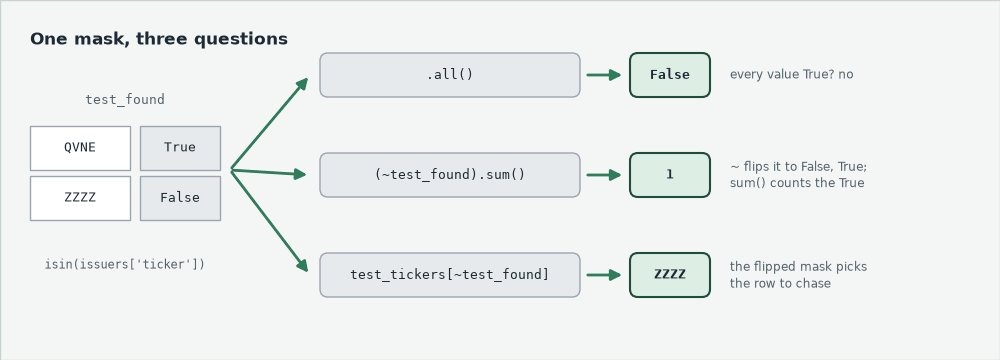

`.all()` answers for the whole column; `~` turns found into not found.

### Every Rating on the Scale?

**Predict 3**

Q. The issuers carry 18 distinct ratings over 150 rows, and the scale lists 18. What does `issuers['rating'].isin(ratings['rating']).all()` return?

A) True.
B) False: 150 is not 18.
C) 18.

In [27]:
# each issuer's rating against the scale, then the positions' tickers against the issuers
rating_found = issuers['rating'].isin(ratings['rating'])
print('Every rating found:', rating_found.all())
found = positions['ticker'].isin(issuers['ticker'])
not_found = ~found
print('Every ticker found:', found.all(), 'Not found:', not_found.sum())

Every rating found: True
Every ticker found: True Not found: 0


A: `isin()` asks one way, whether each of the 150 is among the 18; a text match is exact, so `bbb-` would miss.
Had a ticker been missing, `positions[not_found]` would list the bonds to chase.

Q. Draw the issuers by rating, in credit order.

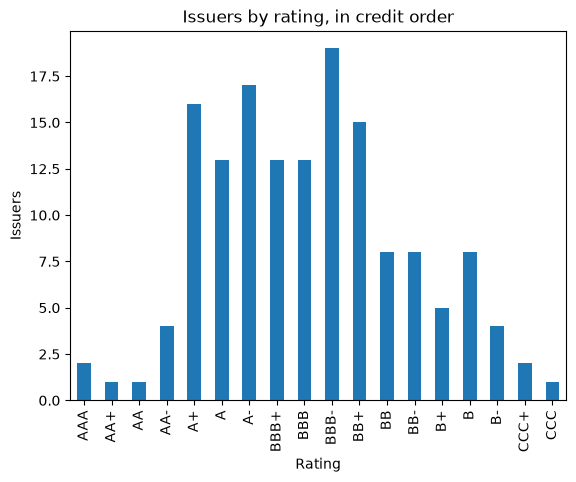

In [28]:
# issuers per rating; loc with the scale's list sets credit order, as in Combining Part 1
by_rating = issuers['rating'].value_counts().loc[ratings['rating'].tolist()]
chart = by_rating.plot.bar(title='Issuers by rating, in credit order',
                           xlabel='Rating', ylabel='Issuers')

BBB- is tallest, 19 issuers on the last investment grade notch; 99 issuers sit at BBB- or better, 51 below.

**Nothing lost at either join: every ticker and every rating is found.**

### Issuers With No Bond

**Predict 4**

Q. The positions hold 115 distinct tickers, every one found among the 150 issuers. How many issuers have no bond in the positions? Write down a number.

In [29]:
# the question turned round: each issuer's ticker against the positions
held = issuers['ticker'].isin(positions['ticker'])
not_held = issuers[~held]
print('Issuers held:', held.sum(), 'Not held:', len(not_held))
not_held.head(3)

Issuers held: 115 Not held: 35


,ticker,issuer,sector,country,rating
16,RULY,Rulvolvey Industrial,Industrials,US,BBB-
17,THAR,Thalentor Chemicals,Materials,US,A
19,MORE,Morvithe Logistics,Transportation,US,B


35: 150 minus the 115 tickers held, not minus the 200, which counts bonds.

**Excel side by side.** Positions sheet: CUSIP in A, ticker in B, a helper in G; an `issuers` sheet with the ticker in A:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Unique key</td><td align="left"><code>positions['cusip'].is_unique</code></td><td align="left"><code>=COUNTA(UNIQUE(A2:A201))=COUNTA(A2:A201)</code>, Excel 2021 and later and Microsoft 365</td></tr>
<tr><td align="left">Found</td><td align="left"><code>positions['ticker'].isin(issuers['ticker'])</code></td><td align="left"><code>=COUNTIF(issuers!A:A, B2)&gt;0</code> in G</td></tr>
<tr><td align="left">All found</td><td align="left"><code>found.all()</code></td><td align="left"><code>=AND(G2:G201)</code></td></tr>
<tr><td align="left">Flip, count</td><td align="left"><code>~found</code>, <code>(~found).sum()</code></td><td align="left"><code>=NOT(G2)</code>, <code>=COUNTIF(G2:G201, FALSE)</code></td></tr>
</table>
<br clear="left">

### The Shape Before the Join

**Predict 5**

Q. Tomorrow the positions (6 columns) join the issuers (5) on `ticker`, then the scale (4) on `rating`, each key kept once. How many columns will the final table have? Write down a number.

In [30]:
# a lookup keeps the rows it starts from; the key is kept once, so one column fewer per join
rows = positions.shape[0]
columns_after_first = positions.shape[1] + issuers.shape[1] - 1
columns_after_second = columns_after_first + ratings.shape[1] - 1
print('After issuers:', (rows, columns_after_first))
print('After ratings:', (rows, columns_after_second))

After issuers: (200, 10)
After ratings: (200, 13)


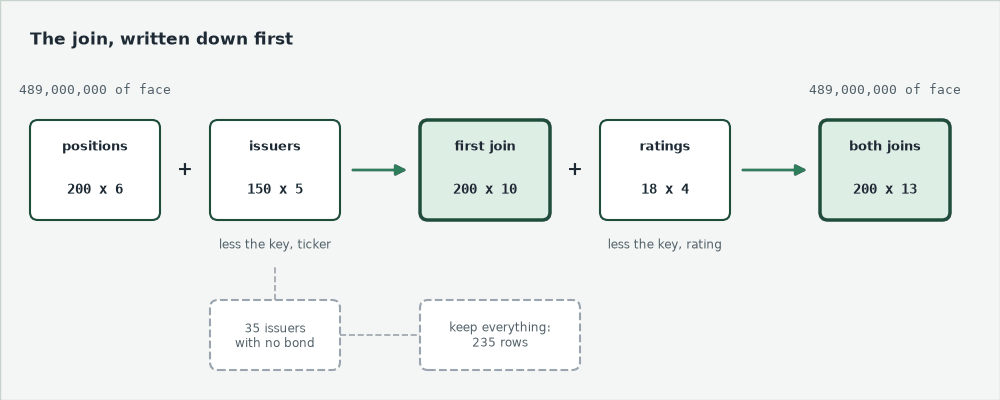

13: 6 plus 5 plus 4, less the two keys kept once.
200 rows: no more, since each key is unique where looked up, and no fewer, since every key is found.

**200 rows, 13 columns, 489,000,000 of face: written down before the join.**

## 9.6 Checks That Run Themselves

Today a person read every True and count; next month nobody will.
As week 1's Day 3 put it, a printed check needs a reader; an `assert` does not.

### Six Checks

Q. Write the tests the joins depend on as `assert` lines.

In [31]:
# nothing missing or repeated in the positions
assert positions.isna().sum().sum() == 0, 'the positions have missing values'
assert positions.duplicated().sum() == 0, 'the positions have repeated rows'
# each lookup key appears once
assert issuers['ticker'].is_unique, 'a ticker appears twice in the issuers table'
assert ratings['rating'].is_unique, 'a rating appears twice on the scale'
# every key looked up is found
assert positions['ticker'].isin(issuers['ticker']).all(), 'a ticker is missing from issuers'
assert issuers['rating'].isin(ratings['rating']).all(), 'a rating is not on the scale'
print('Six checks passed:', positions.shape, issuers.shape, ratings.shape)

Six checks passed: (200, 6) (150, 5) (18, 4)


### A Check That Fails

Q. What does a failure look like? Assert that the ticker is unique in the positions.

In [32]:
# this condition is False: 115 tickers cover 200 rows
assert positions['ticker'].is_unique, 'the ticker repeats, so it cannot identify a bond'

AssertionError: the ticker repeats, so it cannot identify a bond

The message is for someone months from now: say what was expected and what it means.
Run from the top, the notebook stops here.

**Excel side by side.** A check cell, `=IF(COUNTIF(G2:G201, FALSE)=0, "OK", "CHECK")`, shows its result while every other formula calculates on; an `assert` stops the run.

**The findings now run on next month's files, and stop at the first one that fails.**

## Summary

The report to the desk:

<table align="left">
<tr><th align="left"></th><th align="left">positions</th><th align="left">issuers</th><th align="left">ratings</th></tr>
<tr><td align="left">One row is</td><td align="left">one bond held</td><td align="left">one issuer</td><td align="left">one rating</td></tr>
<tr><td align="left">Rows, columns</td><td align="left">200, 6</td><td align="left">150, 5</td><td align="left">18, 4</td></tr>
<tr><td align="left">Missing, repeated</td><td align="left">0, 0</td><td align="left">0, 0</td><td align="left">0, 0</td></tr>
<tr><td align="left">Unique key</td><td align="left"><code>cusip</code></td><td align="left"><code>ticker</code></td><td align="left"><code>rating</code></td></tr>
</table>
<br clear="left">

Every check came back clean: no gap, no repeat, no key without a match.
Clean is still a finding, written down; next month's files must pass the same checks.
Carry forward: the maturity is text, converted only on the side, and a rating averages only through its score.

**The three tables are clean and they fit: ready to join.**

## You Can Now

By the end of this notebook, you can:

* Give any new table the same six-step look, and say what one row stands for.
* Convert date text to dates on the side, leaving the table as it arrived.
* Count gaps and repeated rows with `isna()` and `duplicated()`.
* Count flags down a column, and across a row with `axis=1`.
* Test a key with `is_unique` and `isin()`, and read a mask with `.all()` and `~`.
* Write down what a join should return, and the checks it depends on as `assert` lines.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Combining Part 1's `benchmark.csv`, one row per benchmark bond, with a `cusip`, a `ticker`, and a `rating` among its columns, now gets the same first look.
The issuers are invented.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: the first defines `check`, which marks your answers; the second loads the benchmark and fresh copies of the three tables.

In [33]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [34]:
import os

import pandas as pd

# the benchmark, and fresh copies of the three tables. In Colab they are read from GitHub.
if os.path.exists('../../../data/benchmark.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

benchmark = pd.read_csv(data_folder + 'benchmark.csv')
positions = pd.read_csv(data_folder + 'positions.csv')
issuers = pd.read_csv(data_folder + 'issuers.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(len(benchmark), len(positions), len(issuers), len(ratings))

821 200 150 18


### Exercise 1

Q. Store the benchmark's shape in **ex1_shape**, and the number of its text columns, counted by eye from the types, in **ex1_text_columns**.

In [35]:
ex1_shape = ...
ex1_text_columns = ...

In [36]:
check('Exercise 1 shape', ex1_shape, (821, 19))
check('Exercise 1 text columns', ex1_text_columns, 8)

Exercise 1 shape: not attempted yet
Exercise 1 text columns: not attempted yet


### Exercise 2

Q. How many values are missing in the whole benchmark? How many rows copy an earlier row? Is the CUSIP unique? Store the answers in **ex2_missing**, **ex2_duplicates**, and **ex2_cusip_unique**.

In [37]:
ex2_missing = ...
ex2_duplicates = ...
ex2_cusip_unique = ...

In [38]:
check('Exercise 2 missing', ex2_missing, 0)
check('Exercise 2 duplicates', ex2_duplicates, 0)
check('Exercise 2 CUSIP unique', ex2_cusip_unique, True)

Exercise 2 missing: not attempted yet
Exercise 2 duplicates: not attempted yet
Exercise 2 CUSIP unique: not attempted yet


### Exercise 3

Q. How many distinct tickers does the benchmark have, what is the most bonds any one ticker has, and is every benchmark ticker in the issuers table? Store the answers in **ex3_tickers**, **ex3_most_bonds**, and **ex3_all_found**.

In [39]:
ex3_tickers = ...
ex3_most_bonds = ...
ex3_all_found = ...

In [40]:
check('Exercise 3 tickers', ex3_tickers, 150)
check('Exercise 3 most bonds', ex3_most_bonds, 8)
check('Exercise 3 all found', ex3_all_found, True)

Exercise 3 tickers: not attempted yet
Exercise 3 most bonds: not attempted yet
Exercise 3 all found: not attempted yet


### Exercise 4

Q. With `isin()` on the CUSIP, and no merge: is every position in the benchmark, and how many benchmark bonds does the desk hold, and not hold? Store the answers in **ex4_all_found**, **ex4_held**, and **ex4_not_held**.

In [41]:
ex4_all_found = ...
ex4_held = ...
ex4_not_held = ...

In [42]:
check('Exercise 4 all found', ex4_all_found, True)
check('Exercise 4 held', ex4_held, 200)
check('Exercise 4 not held', ex4_not_held, 621)

Exercise 4 all found: not attempted yet
Exercise 4 held: not attempted yet
Exercise 4 not held: not attempted yet


### Exercise 5

Q. Write `count_not_found(table, lookup, key)`, returning how many rows of `table` have a `key` value missing from that column of `lookup`; replace `return ...` with your code. Use it to count the issuers with no bond, in **ex5_issuers_not_held**, then write one `assert`, with a message, that every position's ticker is in the issuers table.

In [43]:
def count_not_found(table, lookup, key):
    """
    Take two tables and the name of a column they share,
    and return the number of rows of the first table
    whose value in that column is not found in the second table.
    """
    return ...


ex5_issuers_not_held = ...

In [44]:
# the first check calls your function on the benchmark and the positions
check('Exercise 5 benchmark not held', count_not_found(benchmark, positions, 'cusip'), 621)
check('Exercise 5 issuers not held', ex5_issuers_not_held, 35)

Exercise 5 benchmark not held: not attempted yet
Exercise 5 issuers not held: not attempted yet


### Exercise 6

Q. Flag the benchmark bonds priced below 100 (`below_par`), with an OAS above 300 (`wide`), and a duration above 10 (`long`). How many carry all three flags, and how many none? Store the answers in **ex6_all_three** and **ex6_none**.

In [45]:
ex6_all_three = ...
ex6_none = ...

In [46]:
check('Exercise 6 all three', ex6_all_three, 4)
check('Exercise 6 none', ex6_none, 275)

Exercise 6 all three: not attempted yet
Exercise 6 none: not attempted yet


### Exercise 7: AI check

An AI assistant wrote the code below to count the benchmark bonds the desk does not hold.
It was written for this course in the style of an AI answer, and it has one bug.

Q. What number do you expect, from Exercise 4? Run the code. Does it agree?

In [47]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# True for each benchmark bond that the desk holds
held = benchmark['ticker'].isin(positions['ticker'])

# the bonds not held are the ones where held is False
ex7_not_held = (~held).sum()

print(f'Benchmark bonds the desk does not hold: {ex7_not_held}')

Benchmark bonds the desk does not hold: 159


Q. Find the bug and fix the code above, so that **ex7_not_held** holds the right answer.

In [48]:
check('Exercise 7 not held', ex7_not_held, 621)

Exercise 7 not held: not yet. You have 159


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">What each file holds</td><td align="left">one bond held, one issuer, one rating: 200, 150, 18 rows</td></tr>
<tr><td align="left">Missing or doubled</td><td align="left">nothing, in any of the three</td></tr>
<tr><td align="left">The face ties</td><td align="left">489,000,000, as in the holdings file</td></tr>
<tr><td align="left">Bonds to watch</td><td align="left">113 below par, 34 long-dated, 29 small; 7 all three</td></tr>
<tr><td align="left">A clean join</td><td align="left">keys unique and found: 200 rows, 13 columns expected</td></tr>
<tr><td align="left">Checks that run themselves</td><td align="left">six <code>assert</code> lines</td></tr>
</table>
<br clear="left">

Be proud: you did not assume the files fit; you proved it.

Tomorrow the three tables become one book.
Hold it to today's numbers: 200 rows, 13 columns, 489,000,000 of face.